# Distance Profiles

In spatially embedded circuits the chance that two neurons connect, and the strength of the connection, usually depends on the distance between them. A **distance profile** is a function of distance that captures this dependence. Profiles are used in two places:

- `braintools.init.DistanceModulated` multiplies sampled weights by the profile (next tutorial);
- the spatial connectivity builders in `braintools.conn` use it as a connection probability.

Every profile provides three calls:

| Call | Returns |
|---|---|
| `profile.probability(d)` | the profile value at distances `d` |
| `profile.weight_scaling(d)` | the factor used to scale weights; for all built-in profiles this equals `probability(d)` |
| `profile(d)` | shorthand for `weight_scaling(d)` |

The built-in profiles, with the exact formulas they evaluate ($d$ is the distance):

| Profile | Formula | Notes |
|---|---|---|
| `GaussianProfile(sigma)` | $e^{-d^2/2\sigma^2}$ | |
| `ExponentialProfile(decay_constant)` | $e^{-d/\lambda}$ | |
| `PowerLawProfile(exponent, min_distance=1 um)` | $(\max(d, d_0)/d_0)^{-\alpha}$ | equals 1 for $d \le d_0$ |
| `LinearProfile(max_distance)` | $\max(0, 1 - d/d_{max})$ | |
| `StepProfile(threshold, inside_prob=1, outside_prob=0)` | `inside_prob` if $d \le$ threshold, else `outside_prob` | |
| `SigmoidProfile(midpoint, slope)` | $1/(1 + e^{k(d - d_0)})$ | `LogisticProfile(growth_rate, midpoint)` is the same function |
| `DoGProfile(sigma_center, sigma_surround, amplitude_center=1, amplitude_surround=0.5)` | $\max(0,\ A_c e^{-d^2/2\sigma_c^2} - A_s e^{-d^2/2\sigma_s^2})$ | negative part **clipped to 0** |
| `MexicanHatProfile(sigma, amplitude=1)` | $\max(0,\ A(1 - d^2/\sigma^2)e^{-d^2/2\sigma^2})$ | zero for $d \ge \sigma$ |
| `BimodalProfile(sigma1, sigma2, center1, center2, amplitude1, amplitude2)` | sum of two Gaussian bumps at `center1`, `center2` | can exceed 1 |

Most profiles also accept `max_distance`: beyond it the value is set to 0.

## 1. Setup

In [1]:
import brainunit as u
import matplotlib.pyplot as plt
import numpy as np

from braintools import init

d = np.linspace(0.0, 400.0, 801) * u.um  # distances used for the plots
fmt = lambda v: np.array2string(np.asarray(v, dtype=float), precision=4, suppress_small=True)

## 2. Decaying Profiles

The common choice is a profile that starts at 1 and decays with distance. The values printed under the figure check each formula at a characteristic distance.

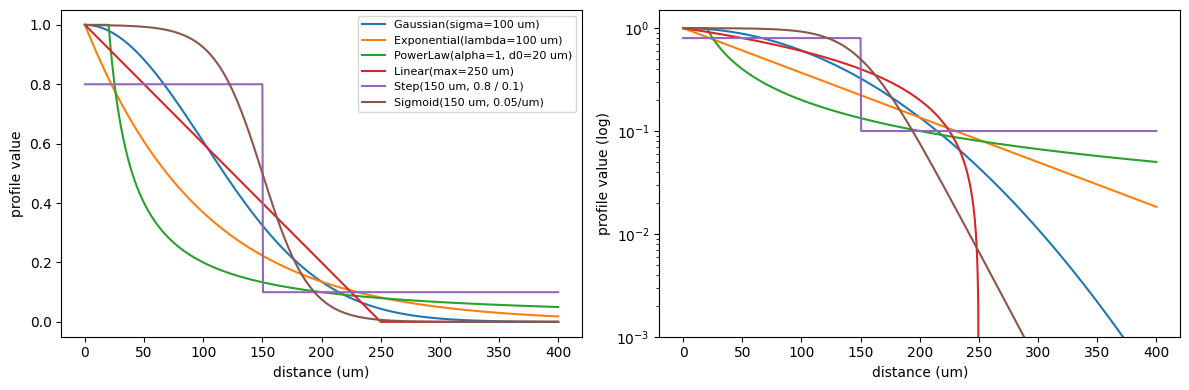

Gaussian at d = sigma:          0.6065  (exp(-1/2) = 0.6065)
Exponential at d = lambda:      0.3679  (exp(-1)   = 0.3679)
PowerLaw at d = 10 um (< d0):   1.0000
PowerLaw at d = 200 um:         0.1000  (20/200   = 0.1)
Linear at d = 125 um:           0.5000
Sigmoid at d = midpoint:        0.5000


In [2]:
decaying = {
    "Gaussian(sigma=100 um)": init.GaussianProfile(sigma=100.0 * u.um),
    "Exponential(lambda=100 um)": init.ExponentialProfile(decay_constant=100.0 * u.um),
    "PowerLaw(alpha=1, d0=20 um)": init.PowerLawProfile(exponent=1.0, min_distance=20.0 * u.um),
    "Linear(max=250 um)": init.LinearProfile(max_distance=250.0 * u.um),
    "Step(150 um, 0.8 / 0.1)": init.StepProfile(threshold=150.0 * u.um, inside_prob=0.8, outside_prob=0.1),
    "Sigmoid(150 um, 0.05/um)": init.SigmoidProfile(midpoint=150.0 * u.um, slope=0.05 / u.um),
}

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
for name, profile in decaying.items():
    axes[0].plot(d.mantissa, profile(d), label=name)
    axes[1].semilogy(d.mantissa, np.maximum(profile(d), 1e-6), label=name)
axes[0].set_ylabel("profile value")
axes[1].set_ylabel("profile value (log)")
axes[1].set_ylim(1e-3, 1.5)
for ax in axes:
    ax.set_xlabel("distance (um)")
axes[0].legend(fontsize=8)
fig.tight_layout()
plt.show()

check = lambda profile, dist: float(profile(np.array([dist]) * u.um)[0])
print(f"Gaussian at d = sigma:          {check(decaying['Gaussian(sigma=100 um)'], 100):.4f}  (exp(-1/2) = {np.exp(-0.5):.4f})")
print(f"Exponential at d = lambda:      {check(decaying['Exponential(lambda=100 um)'], 100):.4f}  (exp(-1)   = {np.exp(-1):.4f})")
print(f"PowerLaw at d = 10 um (< d0):   {check(decaying['PowerLaw(alpha=1, d0=20 um)'], 10):.4f}")
print(f"PowerLaw at d = 200 um:         {check(decaying['PowerLaw(alpha=1, d0=20 um)'], 200):.4f}  (20/200   = 0.1)")
print(f"Linear at d = 125 um:           {check(decaying['Linear(max=250 um)'], 125):.4f}")
print(f"Sigmoid at d = midpoint:        {check(decaying['Sigmoid(150 um, 0.05/um)'], 150):.4f}")

On the log scale the exponential is a straight line, the Gaussian bends downward (its tail is much lighter), and the power law decays slowest at large distances, which is why it is used for sparse long-range connections.

## 3. Units

Distances and profile parameters may use any length units; everything is converted before evaluation, so the same profile gives the same result for distances in micrometres or millimetres.

The one exception to watch is the **steepness** of `SigmoidProfile` / `LogisticProfile`. A plain number is read *per unit of `midpoint`*: `slope=0.05` with `midpoint=150 * u.um` means 0.05 per um, but with `midpoint=0.15 * u.mm` it means 0.05 per mm, a far shallower curve. Give the steepness as a `1/length` quantity (`0.05 / u.um`) to make it unit-independent.

In [3]:
gauss = init.GaussianProfile(sigma=100.0 * u.um)
d_um = np.array([0.0, 50.0, 100.0, 200.0]) * u.um
print("Gaussian, distances in um:", fmt(gauss(d_um)))
print("Gaussian, distances in mm:", fmt(gauss(d_um.to(u.mm))))

print("plain slope, midpoint in um:  ", fmt(init.SigmoidProfile(150.0 * u.um, slope=0.05)(d_um)))
print("plain slope, midpoint in mm:  ", fmt(init.SigmoidProfile(0.15 * u.mm, slope=0.05)(d_um)))
print("slope=0.05/um, midpoint in mm:", fmt(init.SigmoidProfile(0.15 * u.mm, slope=0.05 / u.um)(d_um)))

Gaussian, distances in um: [1.     0.8825 0.6065 0.1353]
Gaussian, distances in mm: [1.     0.8825 0.6065 0.1353]
plain slope, midpoint in um:   [0.9994 0.9933 0.9241 0.0759]
plain slope, midpoint in mm:   [0.5019 0.5012 0.5006 0.4994]
slope=0.05/um, midpoint in mm: [0.9994 0.9933 0.9241 0.0759]


## 4. Center-Surround Shapes

`DoGProfile` and `MexicanHatProfile` describe a positive centre with a negative surround, but because they are probability profiles **their negative part is clipped to 0**. On their own they therefore give a *narrower* positive bump with a cut-off, not an inhibitory surround.

To obtain a signed center-surround function, for example to scale signed weights, compose two Gaussians directly (composition is covered in Section 6); composed profiles are not clipped.

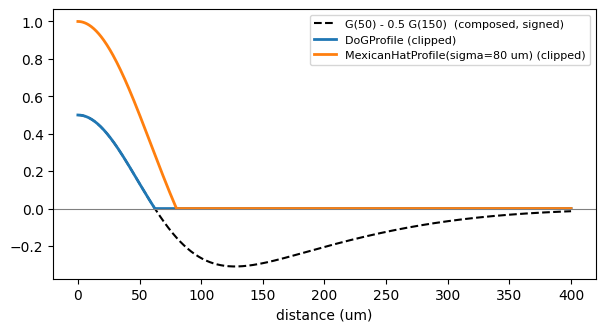

minimum of the composed profile: -0.310
minimum of DoGProfile:           0.000
MexicanHat at d = sigma:         0.000


In [4]:
dog = init.DoGProfile(sigma_center=50.0 * u.um, sigma_surround=150.0 * u.um,
                      amplitude_center=1.0, amplitude_surround=0.5)
signed = init.GaussianProfile(50.0 * u.um) - 0.5 * init.GaussianProfile(150.0 * u.um)
hat = init.MexicanHatProfile(sigma=80.0 * u.um)

fig, ax = plt.subplots(figsize=(7, 3.5))
ax.plot(d.mantissa, signed(d), "k--", label="G(50) - 0.5 G(150)  (composed, signed)")
ax.plot(d.mantissa, dog(d), lw=2, label="DoGProfile (clipped)")
ax.plot(d.mantissa, hat(d), lw=2, label="MexicanHatProfile(sigma=80 um) (clipped)")
ax.axhline(0, color="0.5", lw=0.8)
ax.set_xlabel("distance (um)")
ax.legend(fontsize=8)
plt.show()

print(f"minimum of the composed profile: {float(np.min(signed(d))):.3f}")
print(f"minimum of DoGProfile:           {float(np.min(dog(d))):.3f}")
print(f"MexicanHat at d = sigma:         {float(hat(np.array([80.0]) * u.um)[0]):.3f}")

## 5. Two Spatial Scales: `BimodalProfile`

`BimodalProfile` adds two Gaussian bumps, each with its own centre, width, and amplitude, for example a dense local peak and a weaker band of connections at a characteristic distance. The bumps are summed without normalization, so where they overlap the value can exceed 1; clip it before using it as a probability.

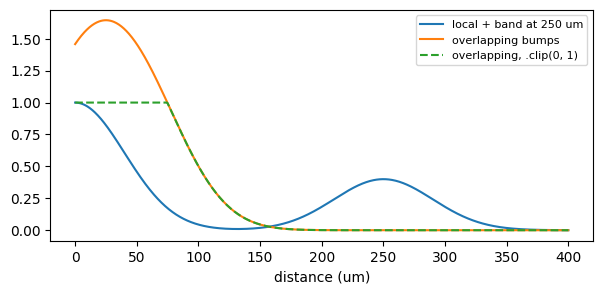

max of overlapping profile: 1.645


In [5]:
bimodal = init.BimodalProfile(sigma1=40.0 * u.um, sigma2=40.0 * u.um,
                              center1=0.0 * u.um, center2=250.0 * u.um,
                              amplitude1=1.0, amplitude2=0.4)
overlapping = init.BimodalProfile(sigma1=40.0 * u.um, sigma2=40.0 * u.um,
                                  center1=0.0 * u.um, center2=50.0 * u.um)

fig, ax = plt.subplots(figsize=(7, 3))
ax.plot(d.mantissa, bimodal(d), label="local + band at 250 um")
ax.plot(d.mantissa, overlapping(d), label="overlapping bumps")
ax.plot(d.mantissa, overlapping.clip(0.0, 1.0)(d), "--", label="overlapping, .clip(0, 1)")
ax.set_xlabel("distance (um)")
ax.legend(fontsize=8)
plt.show()
print(f"max of overlapping profile: {float(np.max(overlapping(d))):.3f}")

## 6. Composing Profiles

Profiles combine with ordinary operators, and the result is again a profile:

| Expression | Meaning |
|---|---|
| `p + q`, `p - q`, `p * q`, `p / q` | pointwise arithmetic of two profiles |
| `0.3 * p`, `p + 0.1` | arithmetic with a constant |
| `p.clip(min_val, max_val)` | bound the values |
| `p.apply(f)` or `p | f` | apply a function to the values |

Composed profiles are **not** clipped automatically: a difference can be negative and a sum can exceed 1. Add `.clip(0, 1)` whenever the result is used as a probability.

In [6]:
local = init.GaussianProfile(sigma=40.0 * u.um)
broad = init.ExponentialProfile(decay_constant=200.0 * u.um)

mixed = (0.8 * local + 0.2 * broad).clip(0.0, 1.0)  # dense local + weak long-range
floor = init.GaussianProfile(sigma=60.0 * u.um).clip(min_val=0.05)  # never below 5 %
squared = init.GaussianProfile(sigma=60.0 * u.um) | (lambda v: v ** 2)  # same as sigma / sqrt(2)

print(mixed)
d_check = np.array([0.0, 100.0, 300.0]) * u.um
print("mixed:  ", fmt(mixed(d_check)))
print("floor:  ", fmt(floor(d_check)))
print("squared:", fmt(squared(d_check)),
      " equals Gaussian(60/sqrt(2)):", np.allclose(squared(d_check), init.GaussianProfile(60.0 / np.sqrt(2) * u.um)(d_check)))

((0.8 * GaussianProfile(sigma=40. um, max_distance=None)) + (0.2 * ExponentialProfile(decay_constant=200. um, max_distance=None))).clip(0.0, 1.0)
mixed:   [1.     0.1565 0.0446]
floor:   [1.     0.2494 0.05  ]
squared: [1.     0.0622 0.    ]  equals Gaussian(60/sqrt(2)): True


## 7. From a Profile to a Connectivity Pattern

When a profile is a connection probability, a connection between two neurons at distance $d$ is drawn with probability $p(d)$. The example places neurons on a 500 um x 500 um sheet, draws connections from a Gaussian profile, and checks that the empirical connection probability as a function of distance matches the profile. `braintools.conn` provides ready-made builders for this (see the connectivity tutorials); the point here is only what the profile means.

47439 connections, 59.3 per neuron


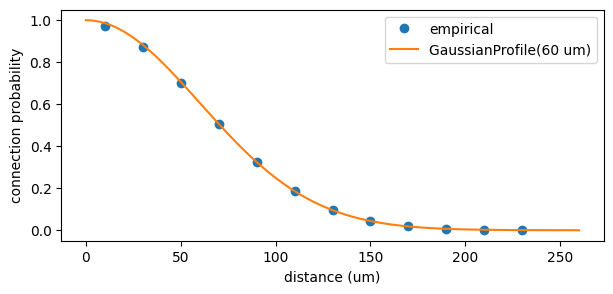

In [7]:
rng = np.random.default_rng(0)
n = 800
pos = rng.uniform(0.0, 500.0, size=(n, 2))
dist = np.linalg.norm(pos[:, None, :] - pos[None, :, :], axis=-1) * u.um

profile = init.GaussianProfile(sigma=60.0 * u.um)
p = np.asarray(profile.probability(dist))
np.fill_diagonal(p, 0.0)  # no self-connections
connected = rng.random(p.shape) < p
print(f"{connected.sum()} connections, {connected.sum() / n:.1f} per neuron")

bins = np.arange(0.0, 260.0, 20.0)
centres = (bins[:-1] + bins[1:]) / 2
dm = dist.mantissa[~np.eye(n, dtype=bool)]
cm = connected[~np.eye(n, dtype=bool)]
idx = np.digitize(dm, bins) - 1
empirical = np.array([cm[idx == k].mean() for k in range(len(centres))])

fig, ax = plt.subplots(figsize=(7, 3))
ax.plot(centres, empirical, "o", label="empirical")
ax.plot(d.mantissa[:521], profile(d[:521]), label="GaussianProfile(60 um)")
ax.set_xlabel("distance (um)")
ax.set_ylabel("connection probability")
ax.legend()
plt.show()

## Summary

- A profile maps distances to values; `probability`, `weight_scaling`, and `profile(d)` all return the same values for the built-in profiles.
- Distances and parameters may use any length units. Give sigmoid steepness as a `1/length` quantity to keep it unit-independent.
- `DoGProfile` and `MexicanHatProfile` clip their negative surround to 0; compose Gaussians for a signed center-surround.
- Profiles compose with `+ - * /`, constants, `.clip`, `.apply`, and `|`; composed profiles are not clipped, so add `.clip(0, 1)` for probabilities.